In [4]:
import pandas as pd
import sqlite3
orders = pd.read_csv("store_orders.csv")
customers = pd.read_csv("store_customers.csv")

In [5]:
con = sqlite3.connect("store.db")

orders.to_sql("orders", con, index=False, if_exists="replace")
customers.to_sql("customers", con, index=False, if_exists="replace")

pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,orders
1,customers


In [6]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [15]:
pd.read_sql("""
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
""", con)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


In [16]:
pd.read_sql("""
SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC
""", con)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


Electronics earn the most per order.

In [17]:
city_spend = pd.read_sql("""
SELECT c.city, SUM(o.amount) AS total_spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
""", con)

In [18]:
city_spend

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [19]:
joined_count = pd.read_sql("""
SELECT COUNT(*) AS joined_rows
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
""", con)
joined_count

,joined_rows
0,195


The orginal order data set has 200 rows of orders. When we run a joined it produces 195 rows of orders. This is because five of the orders did not have a customer ID attached to be able to join the data.

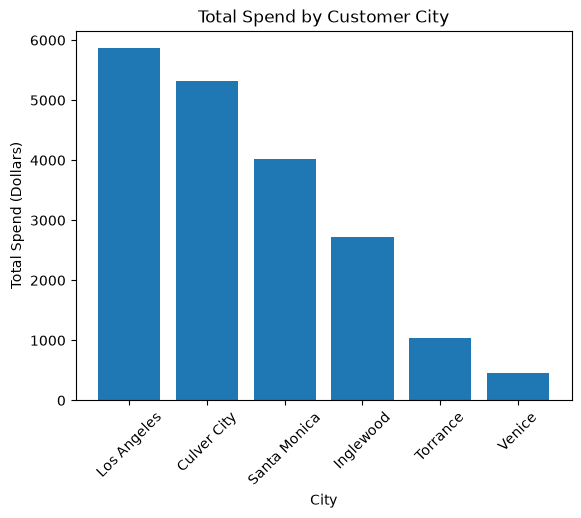

In [20]:
import matplotlib.pyplot as plt
plt.bar(city_spend["city"], city_spend["total_spend"])
plt.title("Total Spend by Customer City")
plt.xlabel("City")
plt.ylabel("Total Spend (Dollars)")
plt.xticks(rotation=45)
plt.show()

What product are customers in Los Angeles buying?

In [21]:
LA_products = pd.read_sql("""
SELECT o.product
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE c.city = 'Los Angeles'
""", con)

LA_products

,product
0,headset
1,monitor
2,paper
3,chair
4,desk
5,headset
6,monitor
7,shelf
8,chair
9,chair


but what are they buying the most in Los Angeles?

In [26]:
la_products = pd.read_sql("""
SELECT o.product, COUNT(*) AS n
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE c.city = 'Los Angeles'
GROUP BY o.product
ORDER BY n DESC
LIMIT 1
""", con)

In [27]:
la_products

,product,n
0,headset,7


The most often ordered product in Los Angeles is headsets at 7 ordered.

Before sharing results publicy, I would remove customer names as well as the customer ID. This will eliminate any identifying information for the clients for their orders.

AI USE:
- help debug query about products bought by customers in Los Angeles
- Helped me resolve the "if replace" error when running notebook.